<a href="https://colab.research.google.com/github/HEINZ-UM/data-science-toolkit/blob/main/Tutorial_4_Data_Science.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial 4 Answer from Heinz Calsia

### Answer 1: Identify the Problem

1. The mentioned dataset is not in tidy format.
2. The 1st rule of tidy-data rule is violated because there should be only one 'Subject' column while the 'Subject' variable is spread across multiple column headers (Math, Science, English), and the values within those columsn represent the "Score".

3. Using Python/pandas to reshape the dataset so that it has the columns:
- Student
- Subject
- Score

In [16]:
import pandas as pd

# First, create the messy dataset
data1 = {
    'Student': ['Ali', 'Sara', 'John'],
    'Math': [75, 88, 65],
    'Science': [80, 91, 70],
    'English': [72, 85, 68]
}
df_messy = pd.DataFrame(data1)

# Second, reshape the dataset
df_tidy = pd.melt(df_messy, id_vars=['Student'], var_name='Subject', value_name='Score')
print(df_tidy)

  Student  Subject  Score
0     Ali     Math     75
1    Sara     Math     88
2    John     Math     65
3     Ali  Science     80
4    Sara  Science     91
5    John  Science     70
6     Ali  English     72
7    Sara  English     85
8    John  English     68


### Answer 2: Sales Data

1. The main tidy-data problem is that values (the quarters: Q1, Q2, Q3, Q4) are stored as column headers (Q1_Sales, Q2_Sales, etc.) instead of being stored in a single variable column. Additionally, the column headers contain two separate pieces of information mixed together: the time period (Quarter) and the metric being measured (Sales). In tidy data, each variable must have its own dedicated column

2. Pandas code to tidy up the dataset

In [15]:
# Step 1: Recreating the messy dataset

data2 = {
    'Country': ['Malaysia', 'Thailand', 'Indonesia'],
    'Q1_Sales':[12000, 10000, 14000],
    'Q2_Sales':[15000, 11000, 12500],
    'Q3_Sales':[14000, 13000, 15000],
    'Q4_Sales': [18000, 16000, 17000]
}
df_messy2 = pd.DataFrame(data2)

# Step 2: Use melt to reshape the columns into rows
df_tidy2 = pd.melt(df_messy2, id_vars=['Country'], var_name='Quarter', value_name='Sales')

# Step 3: Clean up 'Qn_sales' to just 'Qn'
df_tidy2['Quarter'] = df_tidy2['Quarter'].str.replace('_Sales', '')
print(df_tidy2.head(3))

     Country Quarter  Sales
0   Malaysia      Q1  12000
1   Thailand      Q1  10000
2  Indonesia      Q1  14000


### Answer 3: Asking Questions from Data

In [12]:
data3 = {
    "Student": ["A", "B", "C", "D", "E", "F"],
    "Study_Hours": [2, 5, 3, 7, 4, 8],
    "Score": [55, 72, 60, 85, 68, 90]
}
df3 = pd.DataFrame(data3)

# 1. The average study hours
avg_study_time = df3['Study_Hours'].mean()
print(f"1. Average study time: {avg_study_time:.2f} hours")

# 2. Average Score
avg_score = df3['Score'].mean()
print(f"2. Average score: {avg_score:.2f}")

# 3. Student with the highest score
highest_score_student = df3.loc[df3['Score'].idxmax(), 'Student']
print(f"3. Student with the highest score: {highest_score_student}")

# 4. Student who studied the most
most_studied_student = df3.loc[df3['Study_Hours'].idxmax(), 'Student']
print(f"4. Student who studied the most: {most_studied_student}")

1. Average study time: 4.83 hours
2. Average score: 71.67
3. Student with the highest score: F
4. Student who studied the most: F


5. There is a clear positive coorelation between study hours and high scores. Sorting the data shows that as study hours increase (2-3-4-5-7-8), the scores also steadily rise (55-60-68-72-85-90).

6. By using matplotlib to visualize the scatter plot of Study Hours vs. Score, we can see the strong upward linear trend between study duration and exam result.

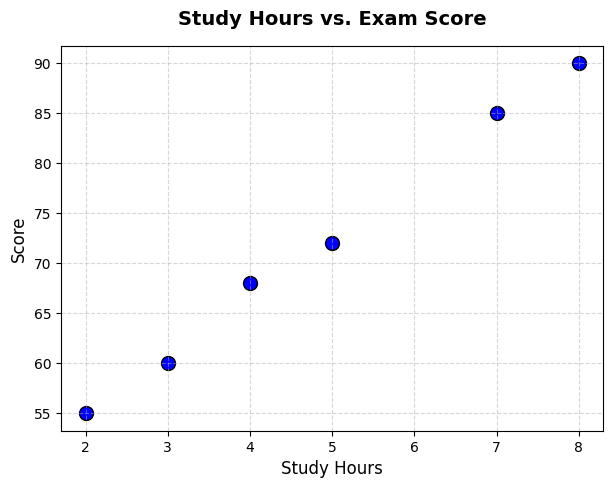

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

# 3. Create the scatter plot (X-axis variable, Y-axis variable)
plt.scatter(df3['Study_Hours'], df3['Score'], color='blue', edgecolor='black', s=100)

# 4. Add titles and axis labels
plt.title("Study Hours vs. Exam Score", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Study Hours", fontsize=12)
plt.ylabel("Score", fontsize=12)

# 5. Optional: Add a clean grid layout background
plt.grid(True, linestyle='--', alpha=0.5)

# 6. Display the plot window on your desktop
plt.show()